In [5]:
import numpy as np
import torch
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import torch.nn as nn
import os
from torch.utils.data import DataLoader

In [6]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print(f"using device: {device}")

using device: mps


torch.Size([64, 1, 28, 28])
torch.Size([64])
torch.Size([3, 1, 28, 28])
tensor([0, 4, 4])


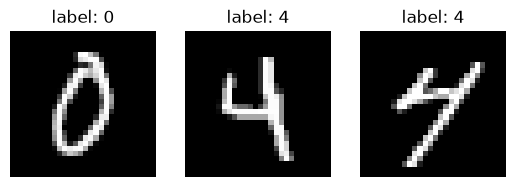

In [7]:
data_dir = os.path.expanduser("~/data")

train_data = datasets.MNIST(
    root=data_dir,
    train=True,
    download=True,
    transform=transforms.ToTensor(),
)
test_data = datasets.MNIST(
    root=data_dir,
    train=False,
    download=True,
    transform=transforms.ToTensor(),
)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=True)

images, labels = next(iter(train_loader))
test_images, test_labels = next(iter(test_loader))

print(images.shape)
print(labels.shape)

print(images[:3].shape)
print(labels[:3])

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(f"label: {labels[i].item()}")
    plt.axis("off")
plt.show()

epoch 0: loss 0.2838, lr 0.000973
epoch 1: loss 0.1099, lr 0.000757
epoch 2: loss 0.1473, lr 0.000418
epoch 3: loss 0.1012, lr 0.000119
epoch 4: loss 0.0919, lr 0.000000
test accuracy: 0.9828


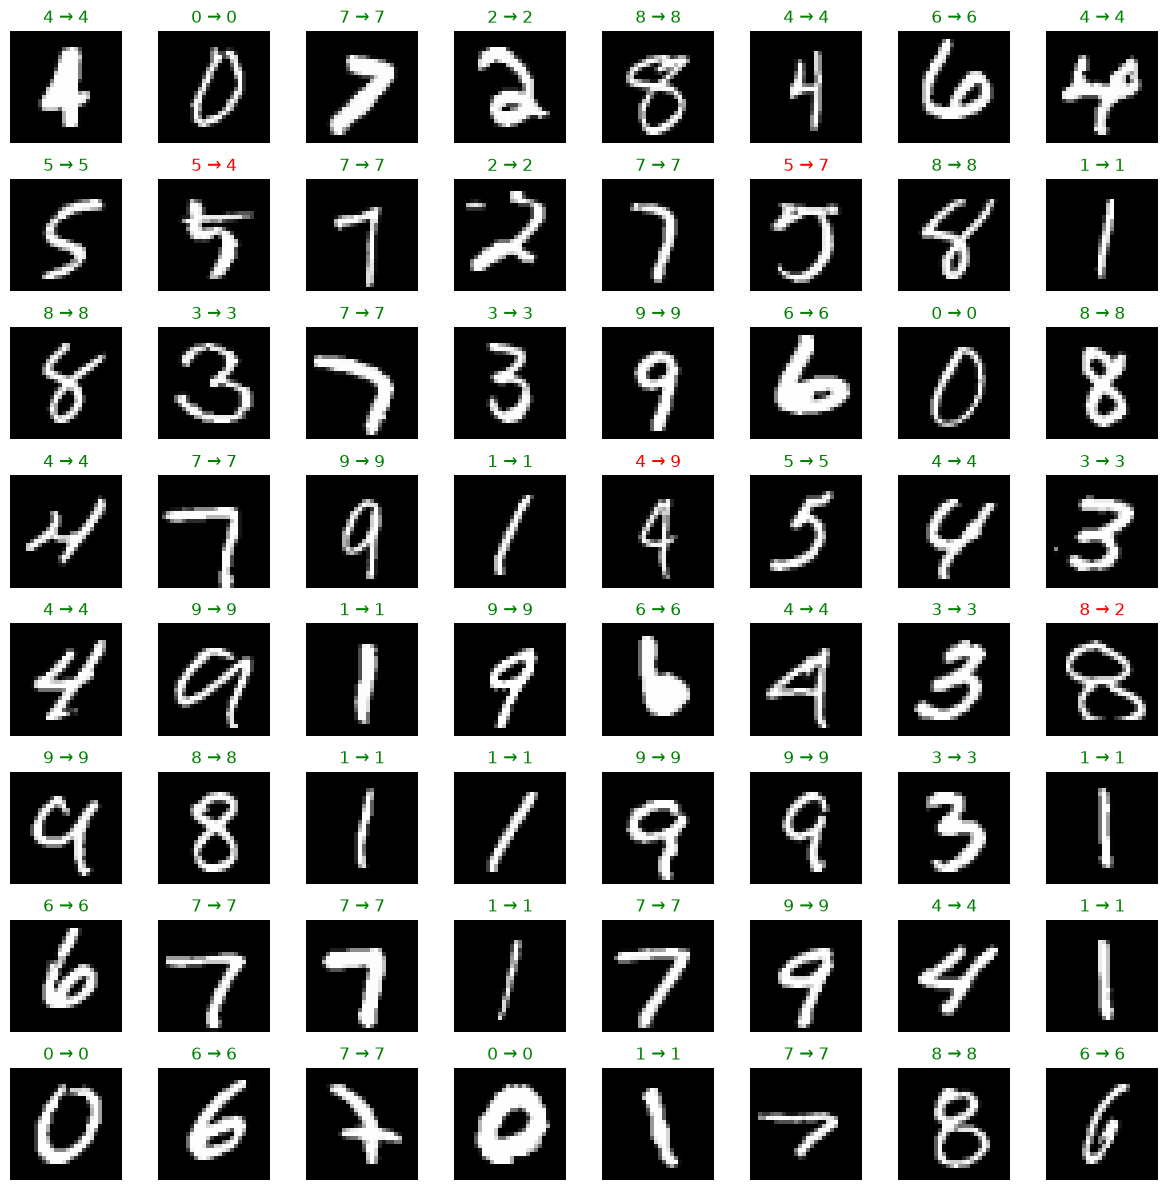

In [11]:
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256),
    nn.BatchNorm1d(256),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(256, 128),
    nn.BatchNorm1d(128),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(128, 10)
)

model.to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)

epochs = 5
total_steps = epochs * len(train_loader)
warmup_steps = 500

warmup = torch.optim.lr_scheduler.LinearLR(
    optimizer, start_factor=0.01, end_factor=1.0, total_iters=warmup_steps
)

cosine = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=total_steps - warmup_steps
)

scheduler = torch.optim.lr_scheduler.SequentialLR(
    optimizer, schedulers=[warmup, cosine], milestones=[warmup_steps]
)

for epoch in range(epochs):
    model.train()
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        z = model(images)
        loss = loss_fn(z, labels)
        loss.backward()
        optimizer.step()
        scheduler.step()
    print(f"epoch {epoch}: loss {loss.item():.4f}, lr {scheduler.get_last_lr()[0]:.6f}")

model.eval()

correct = 0
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        pred = torch.argmax(model(images), dim=1)
        correct += (pred == labels).sum().item()
print(f"test accuracy: {correct / len(test_data):.4f}")

test_images, test_labels = next(iter(test_loader))
with torch.no_grad():
    z = model(test_images.to(device))
    pred = torch.argmax(z, dim=1).cpu()

plt.figure(figsize=(12, 12))
for i in range(64):
    plt.subplot(8, 8, i + 1)
    plt.imshow(test_images[i].squeeze(), cmap="gray")
    if test_labels[i] == pred[i]:
        color = "green"
    else:
        color = "red"
    plt.title(f"{test_labels[i].item()} → {pred[i].item()}", color=color)
    plt.axis("off")
plt.tight_layout()
plt.show()